## Flight Price Prediction
### Project: PRCP-1025 - Flight Price Prediction Type: Supervised Machine Learning - Regression Tools: Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn

#### 1.Contents
#### 2.Project Introduction
#### 3.Data Loading & Initial Understanding
#### 4.Exploratory Data Analysis (EDA)
#### 5.Data Preprocessing & Feature Engineering
#### 6.Feature Encoding & Feature Selection
#### 7.Train-Test Split
#### 8.Model Building
#### 9.Model Evaluation
#### 10.Model Selection
#### 11.Hyperparameter Tuning
#### 12.Final Model Evaluation
#### 13.Sample Prediction
#### 14.Challenges & Solutions
#### 15.Final Conclusion


#  1. Project Introduction

### Business Problem

Flight ticket prices change frequently. The same route can cost a different amount today and tomorrow, making it difficult for travellers to know whether a price is reasonable. Airlines and travel websites also want to understand which factors influence the price of a ticket.

### Objective

The objectives of this project are:

- Prepare a complete **Exploratory Data Analysis (EDA)** report on the flight fare dataset.
- Build a **predictive model** that estimates the ticket price from flight details, helping customers plan their journey.
- Compare multiple machine learning models and identify a suitable model for production.
- Document the challenges faced in the data and the techniques used to address them.

### Why Is Flight Price Prediction Useful?

- **For Customers:** Helps travellers determine whether a ticket price is reasonable and plan their travel budget.
- **For Travel Websites:** Can be used to show users an expected or estimated flight price.
- **For Airlines:** Helps understand factors that influence ticket prices, such as airline, number of stops, duration, and travel date, which can support pricing analysis.

## ML Problem Definition

We have historical flight records along with their corresponding ticket prices, so this is a **Supervised Learning** problem.

The target variable, **Price**, is a continuous numerical value representing the ticket price in Indian Rupees. Therefore, this is a **Regression** problem rather than a Classification problem.

### Target Variable and Features

| Column | Meaning |
|---|---|
| **Airline** | Name of the airline (IndiGo, Jet Airways, Air India, ...) |
| **Date_of_Journey** | Date the journey starts |
| **Source** | City where the journey starts |
| **Destination** | City where the journey ends |
| **Route** | Airports the flight passes through |
| **Dep_Time** | Departure time |
| **Arrival_Time** | Arrival time |
| **Duration** | Total time of the journey |
| **Total_Stops** | Number of stops between source and destination |
| **Additional_Info** | Extra information such as meal, baggage, layover, etc. |
| **Price** | **Target variable — ticket price we want to predict** |

### Project Workflow

**Data Collection → Data Understanding → Data Cleaning → EDA → Feature Engineering → Data Preprocessing → Model Building → Model Evaluation → Model Comparison → Final Prediction**

# 2. Data Loading & Initial Understanding


In [26]:
# Basic libraries for data handling
import numpy as np
import pandas as pd

# Libraries for visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Libraries for visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn: splitting, encoding, models, tuning and metrics
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Display settings
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
BAR_COLOR = '#4C72B0'   # one colour for all simple charts, so the notebook looks consistent

In [3]:
# Load the dataset
df=pd.read_excel("Flight_Fare.xlsx")
df

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302
...,...,...,...,...,...,...,...,...,...,...,...
10678,Air Asia,9/04/2019,Kolkata,Banglore,CCU → BLR,19:55,22:25,2h 30m,non-stop,No info,4107
10679,Air India,27/04/2019,Kolkata,Banglore,CCU → BLR,20:45,23:20,2h 35m,non-stop,No info,4145
10680,Jet Airways,27/04/2019,Banglore,Delhi,BLR → DEL,08:20,11:20,3h,non-stop,No info,7229
10681,Vistara,01/03/2019,Banglore,New Delhi,BLR → DEL,11:30,14:10,2h 40m,non-stop,No info,12648


In [5]:
print('Shape of the dataset:', df.shape)
print('Rows   :', df.shape[0]) # Records
print('Columns:', df.shape[1]) # Columns

Shape of the dataset: (10683, 11)
Rows   : 10683
Columns: 11


In [7]:
# First Five records
df.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [8]:
# Last five records
df.tail()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
10678,Air Asia,9/04/2019,Kolkata,Banglore,CCU → BLR,19:55,22:25,2h 30m,non-stop,No info,4107
10679,Air India,27/04/2019,Kolkata,Banglore,CCU → BLR,20:45,23:20,2h 35m,non-stop,No info,4145
10680,Jet Airways,27/04/2019,Banglore,Delhi,BLR → DEL,08:20,11:20,3h,non-stop,No info,7229
10681,Vistara,01/03/2019,Banglore,New Delhi,BLR → DEL,11:30,14:10,2h 40m,non-stop,No info,12648
10682,Air India,9/05/2019,Delhi,Cochin,DEL → GOI → BOM → COK,10:55,19:15,8h 20m,2 stops,No info,11753


In [9]:
# Column names, data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10683 non-null  object
 1   Date_of_Journey  10683 non-null  object
 2   Source           10683 non-null  object
 3   Destination      10683 non-null  object
 4   Route            10682 non-null  object
 5   Dep_Time         10683 non-null  object
 6   Arrival_Time     10683 non-null  object
 7   Duration         10683 non-null  object
 8   Total_Stops      10682 non-null  object
 9   Additional_Info  10683 non-null  object
 10  Price            10683 non-null  int64 
dtypes: int64(1), object(10)
memory usage: 918.2+ KB


In [10]:
# Statistical summary of the numeric column (Price) 
df.describe()

,Price
count,10683.000000
mean,9087.064121
std,4611.359167
min,1759.000000
25%,5277.000000
50%,8372.000000
75%,12373.000000
max,79512.000000


In [13]:
# Summary of the text (categorical) columns
df.describe(include='object')

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info
count,10683,10683,10683,10683,10682,10683,10683,10683,10682,10683
unique,12,44,5,6,128,222,1343,368,5,10
top,Jet Airways,18/05/2019,Delhi,Cochin,DEL → BOM → COK,18:55,19:00,2h 50m,1 stop,No info
freq,3849,504,4537,4537,2376,233,423,550,5625,8345


In [19]:
# Missing values in each column
missing = df.isnull().sum()
missing_percent = (missing / len(df)) * 100
pd.DataFrame({'Missing Count': missing})

,Missing Count
Airline,0
Date_of_Journey,0
Source,0
Destination,0
Route,1
Dep_Time,0
Arrival_Time,0
Duration,0
Total_Stops,1
Additional_Info,0


In [20]:
# Show the row(s) that contain missing values
df[df.isnull().any(axis=1)]

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
9039,Air India,6/05/2019,Delhi,Cochin,NaN,09:45,09:25 07 May,23h 40m,NaN,No info,7480


#### Observation: 
Only 1 row has missing values, and it is the same row for both Route and Total_Stops. That is less than 0.01% of the data, so removing it will not lose any useful information.

In [21]:
# Duplicate rows (all 11 columns exactly the same)
print('Number of duplicate rows:', df.duplicated().sum())

Number of duplicate rows: 220


In [22]:
# Number of unique values in each column
df.nunique().sort_values()

Source                5
Total_Stops           5
Destination           6
Additional_Info      10
Airline              12
Date_of_Journey      44
Route               128
Dep_Time            222
Duration            368
Arrival_Time       1343
Price              1870
dtype: int64

In [23]:
# Look at the categories of the low-cardinality columns
for col in ['Airline', 'Source', 'Destination', 'Total_Stops', 'Additional_Info']:
    print(f'----- {col} -----')
    print(df[col].value_counts(dropna=False))
    print()

----- Airline -----
Airline
Jet Airways                          3849
IndiGo                               2053
Air India                            1752
Multiple carriers                    1196
SpiceJet                              818
Vistara                               479
Air Asia                              319
GoAir                                 194
Multiple carriers Premium economy      13
Jet Airways Business                    6
Vistara Premium economy                 3
Trujet                                  1
Name: count, dtype: int64

----- Source -----
Source
Delhi       4537
Kolkata     2871
Banglore    2197
Mumbai       697
Chennai      381
Name: count, dtype: int64

----- Destination -----
Destination
Cochin       4537
Banglore     2871
Delhi        1265
New Delhi     932
Hyderabad     697
Kolkata       381
Name: count, dtype: int64

----- Total_Stops -----
Total_Stops
1 stop      5625
non-stop    3491
2 stops     1520
3 stops       45
NaN            1
4 stops    

# 3. Exploratory Data Analysis (EDA)

In [24]:
eda_df = df.copy()

### Price (target variable)

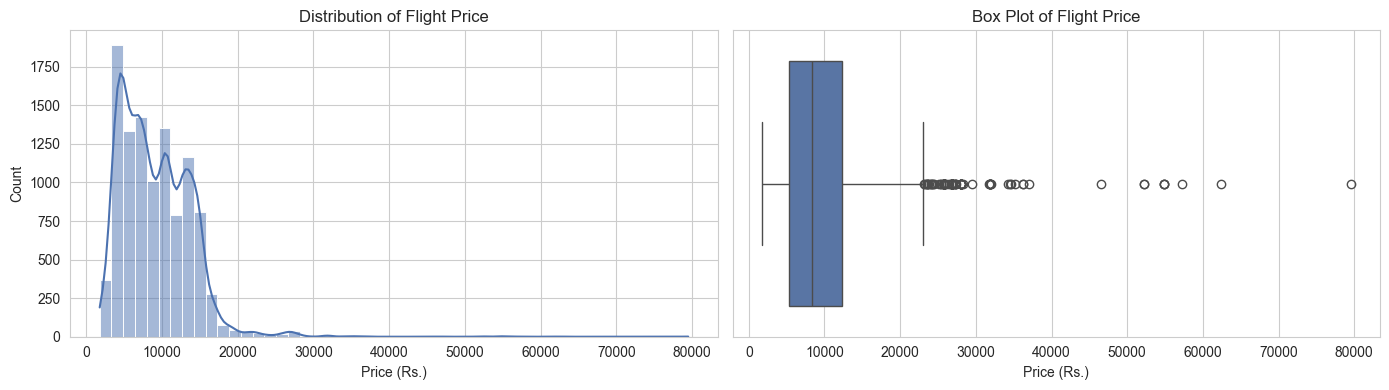

Skewness of Price: 1.81


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Histogram with a density curve
sns.histplot(eda_df['Price'], bins=50, kde=True, color=BAR_COLOR, ax=axes[0])
axes[0].set_title('Distribution of Flight Price')
axes[0].set_xlabel('Price (Rs.)')

# Box plot to see outliers
sns.boxplot(x=eda_df['Price'], color=BAR_COLOR, ax=axes[1])
axes[1].set_title('Box Plot of Flight Price')
axes[1].set_xlabel('Price (Rs.)')

plt.tight_layout()
plt.show()

print('Skewness of Price:', round(eda_df['Price'].skew(), 2))

### Airline

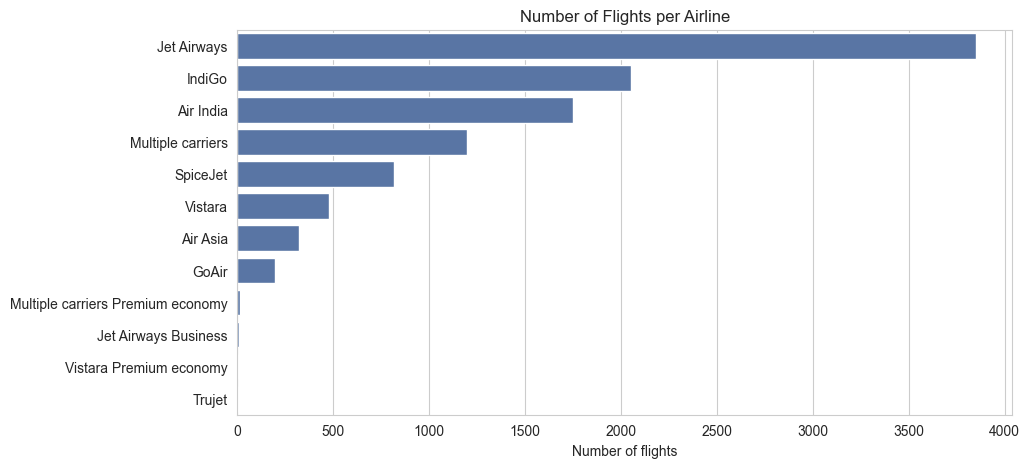

In [30]:
plt.figure(figsize=(10, 5))
airline_order = eda_df['Airline'].value_counts().index
sns.countplot(data=eda_df, y='Airline', order=airline_order, color=BAR_COLOR)
plt.title('Number of Flights per Airline')
plt.xlabel('Number of flights')
plt.ylabel('')
plt.show()

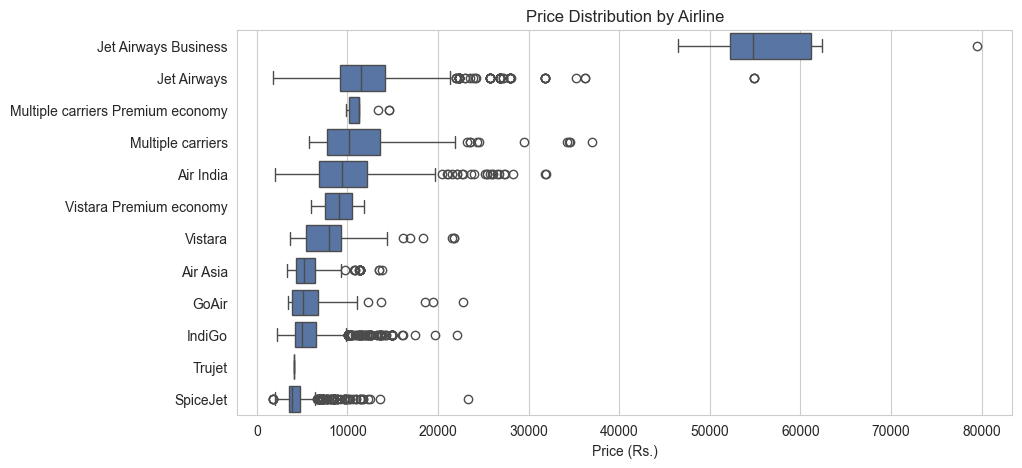

In [31]:
plt.figure(figsize=(10, 5))
# Order airlines by their median price (highest first)
price_order = eda_df.groupby('Airline')['Price'].median().sort_values(ascending=False).index
sns.boxplot(data=eda_df, x='Price', y='Airline', order=price_order, color=BAR_COLOR)
plt.title('Price Distribution by Airline')
plt.xlabel('Price (Rs.)')
plt.ylabel('')
plt.show()

### Insight

* **Jet Airways Business** falls into a significantly different price range, with a median price of approximately **₹54,700**, which is expected because it represents business-class travel.
* Among the regular airlines, **Jet Airways** (median ≈ **₹11,500**) and **Multiple carriers** have relatively higher median prices.
* **SpiceJet, IndiGo, GoAir, and Air Asia** fall into the lower price range, with median prices of approximately **₹3,900–₹5,200**.
* This analysis suggests that **Airline is an important feature** for predicting flight ticket prices.


### Date_of_Journey

In [33]:
# Quick conversion of the date text (format is day/month/year) - only for EDA
eda_df['Journey_Date'] = pd.to_datetime(eda_df['Date_of_Journey'], format='%d/%m/%Y')
eda_df['Journey_Day'] = eda_df['Journey_Date'].dt.day
eda_df['Journey_Month'] = eda_df['Journey_Date'].dt.month

print('Years present :', eda_df['Journey_Date'].dt.year.unique())
print('Months present:', sorted(eda_df['Journey_Month'].unique().tolist()))
print('Days present  :', sorted(eda_df['Journey_Day'].unique().tolist()))

Years present : [2019]
Months present: [3, 4, 5, 6]
Days present  : [1, 3, 6, 9, 12, 15, 18, 21, 24, 27]


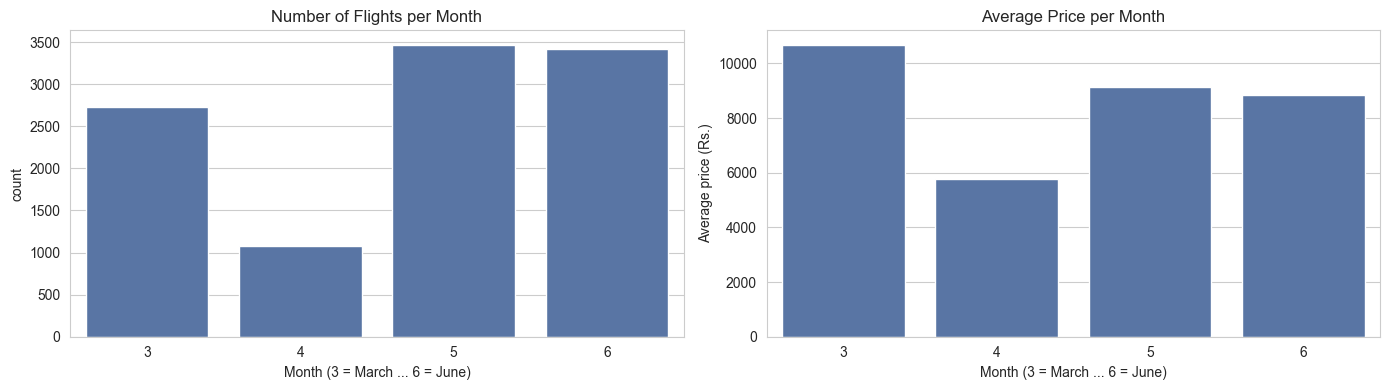

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.countplot(data=eda_df, x='Journey_Month', color=BAR_COLOR, ax=axes[0])
axes[0].set_title('Number of Flights per Month')
axes[0].set_xlabel('Month (3 = March ... 6 = June)')

sns.barplot(data=eda_df, x='Journey_Month', y='Price', estimator='mean', errorbar=None, color=BAR_COLOR, ax=axes[1])
axes[1].set_title('Average Price per Month')
axes[1].set_xlabel('Month (3 = March ... 6 = June)')
axes[1].set_ylabel('Average price (Rs.)')

plt.tight_layout()
plt.show()

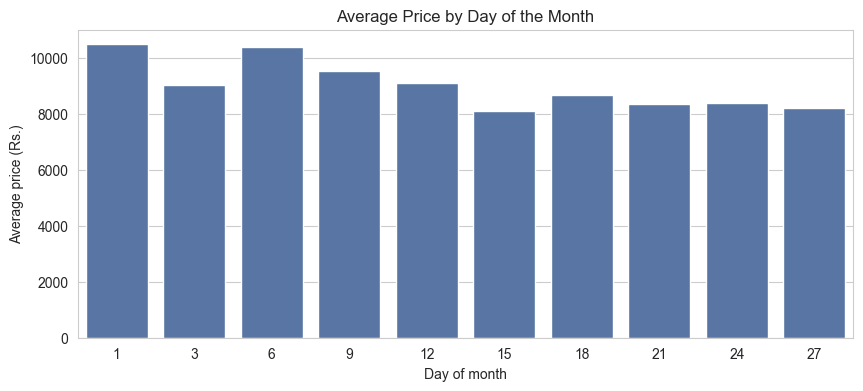

In [36]:
plt.figure(figsize=(10, 4))
sns.barplot(data=eda_df, x='Journey_Day', y='Price', estimator='mean', errorbar=None, color=BAR_COLOR)
plt.title('Average Price by Day of the Month')
plt.xlabel('Day of month')
plt.ylabel('Average price (Rs.)')
plt.show()

### Source and Destination

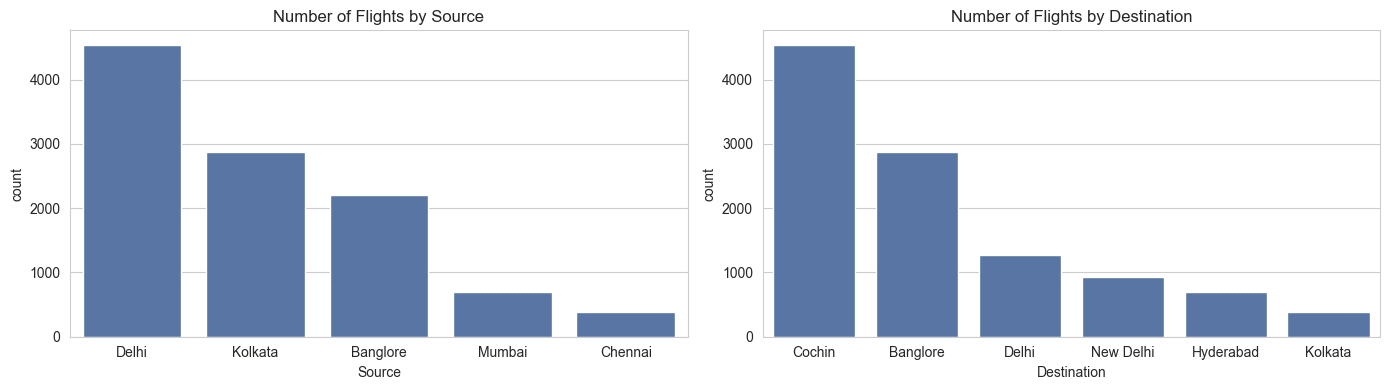

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.countplot(data=eda_df, x='Source', order=eda_df['Source'].value_counts().index, color=BAR_COLOR, ax=axes[0])
axes[0].set_title('Number of Flights by Source')

sns.countplot(data=eda_df, x='Destination', order=eda_df['Destination'].value_counts().index, color=BAR_COLOR, ax=axes[1])
axes[1].set_title('Number of Flights by Destination')

plt.tight_layout()
plt.show()

In [38]:
# Which source goes to which destination?
pd.crosstab(eda_df['Source'], eda_df['Destination'])

Destination,Banglore,Cochin,Delhi,Hyderabad,Kolkata,New Delhi
Source,,,,,,
Banglore,0,0,1265,0,0,932
Chennai,0,0,0,0,381,0
Delhi,0,4537,0,0,0,0
Kolkata,2871,0,0,0,0,0
Mumbai,0,0,0,697,0,0


**Insight:**
- There are only **6 source-destination pairs** in the whole dataset. For example, every flight from Delhi goes to Cochin
  (4,537 flights), and every flight from Kolkata goes to Banglore.
- Flights from **Banglore** go to either "Delhi" or "New Delhi". Let's check why there are two names.

In [40]:
# Banglore flights: destination name vs month of journey
banglore = eda_df[eda_df['Source'] == 'Banglore']
pd.crosstab(banglore['Destination'], banglore['Journey_Month'])

Journey_Month,3,4,5,6
Destination,,,,
Delhi,0,423,424,418
New Delhi,932,0,0,0


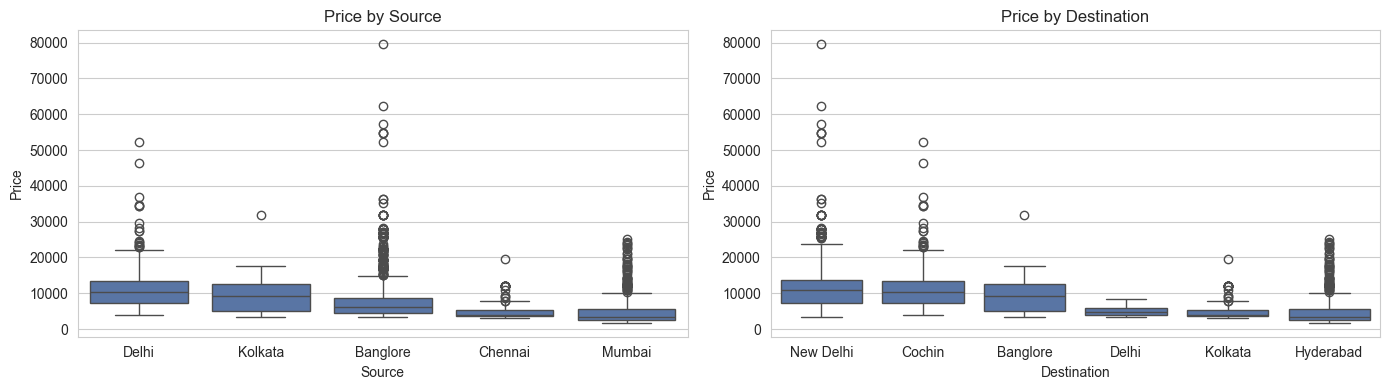

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

source_order = eda_df.groupby('Source')['Price'].median().sort_values(ascending=False).index
sns.boxplot(data=eda_df, x='Source', y='Price', order=source_order, color=BAR_COLOR, ax=axes[0])
axes[0].set_title('Price by Source')

dest_order = eda_df.groupby('Destination')['Price'].median().sort_values(ascending=False).index
sns.boxplot(data=eda_df, x='Destination', y='Price', order=dest_order, color=BAR_COLOR, ax=axes[1])
axes[1].set_title('Price by Destination')

plt.tight_layout()
plt.show()

### Route

Number of unique routes: 128


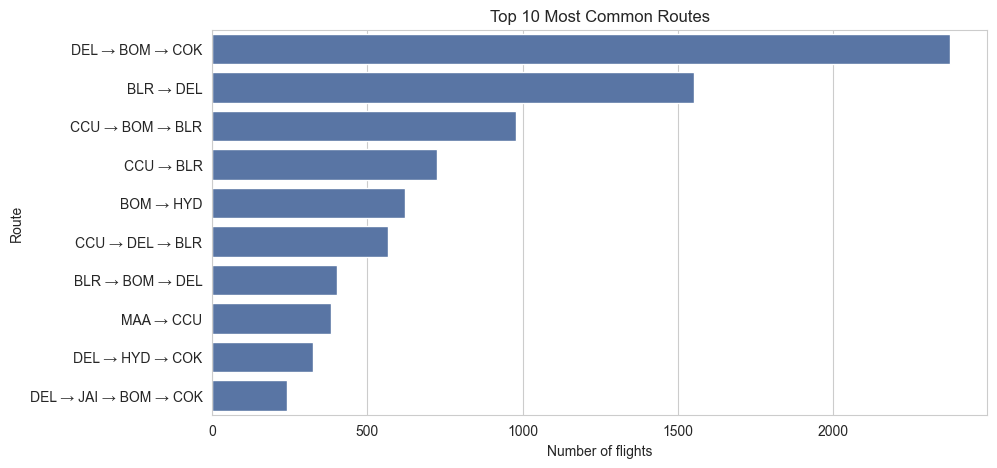

In [42]:
print('Number of unique routes:', eda_df['Route'].nunique())

plt.figure(figsize=(10, 5))
top_routes = eda_df['Route'].value_counts().head(10)
sns.barplot(x=top_routes.values, y=top_routes.index, color=BAR_COLOR)
plt.title('Top 10 Most Common Routes')
plt.xlabel('Number of flights')
plt.show()

### Departure time and Arrival_Time

In [43]:
# Some arrival times also contain a date, e.g. '01:10 22 Mar' (the flight lands on the next day)
with_date = eda_df['Arrival_Time'].str.len() > 5
print('Arrival times that include a date:', with_date.sum())
eda_df.loc[with_date, 'Arrival_Time'].head()

Arrival times that include a date: 4335


0    01:10 22 Mar
2    04:25 10 Jun
6    10:25 13 Mar
7    05:05 02 Mar
8    10:25 13 Mar
Name: Arrival_Time, dtype: object

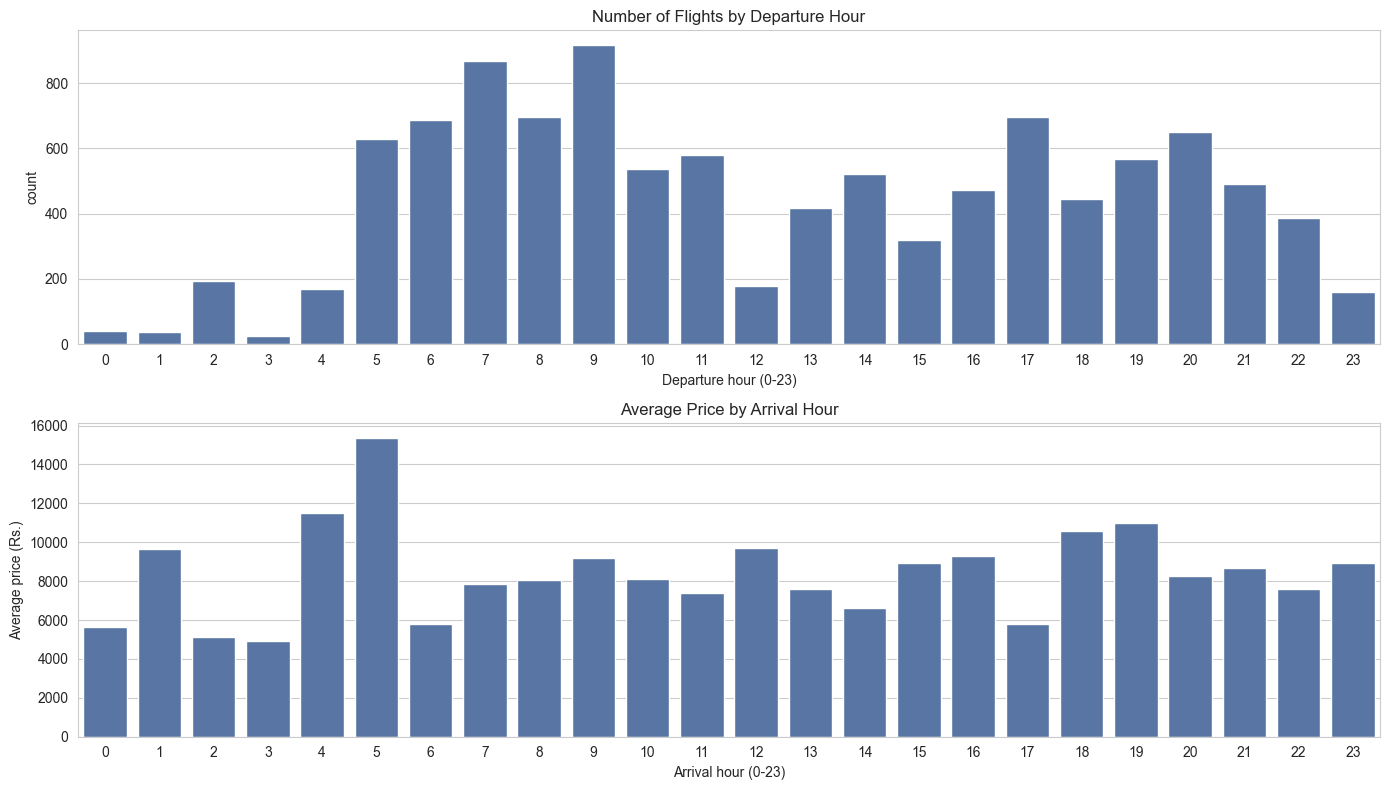

In [44]:
# Quick conversion to hour - only for EDA. For Arrival_Time we keep only the part before the space ('01:10')
eda_df['Dep_Hour'] = pd.to_datetime(eda_df['Dep_Time'], format='%H:%M').dt.hour
eda_df['Arrival_Hour'] = pd.to_datetime(eda_df['Arrival_Time'].str.split(' ').str[0], format='%H:%M').dt.hour

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

sns.countplot(data=eda_df, x='Dep_Hour', color=BAR_COLOR, ax=axes[0])
axes[0].set_title('Number of Flights by Departure Hour')
axes[0].set_xlabel('Departure hour (0-23)')

sns.barplot(data=eda_df, x='Arrival_Hour', y='Price', estimator='mean', errorbar=None, color=BAR_COLOR, ax=axes[1])
axes[1].set_title('Average Price by Arrival Hour')
axes[1].set_xlabel('Arrival hour (0-23)')
axes[1].set_ylabel('Average price (Rs.)')

plt.tight_layout()
plt.show()

### Duration

In [45]:
# Duration is text like '2h 50m', '19h' or '5m'. This function converts it to total minutes.
def duration_to_minutes(duration):
    hours = 0
    minutes = 0
    for part in duration.split():        # '2h 50m' -> ['2h', '50m']
        if 'h' in part:
            hours = int(part.replace('h', ''))
        elif 'm' in part:
            minutes = int(part.replace('m', ''))
    return hours * 60 + minutes

# Check the function on the different formats
print(duration_to_minutes('2h 50m'), duration_to_minutes('19h'), duration_to_minutes('5m'))

eda_df['Duration_Mins'] = eda_df['Duration'].apply(duration_to_minutes)
eda_df['Duration_Mins'].describe()

170 1140 5


count    10683.000000
mean       643.093232
std        507.862001
min          5.000000
25%        170.000000
50%        520.000000
75%        930.000000
max       2860.000000
Name: Duration_Mins, dtype: float64

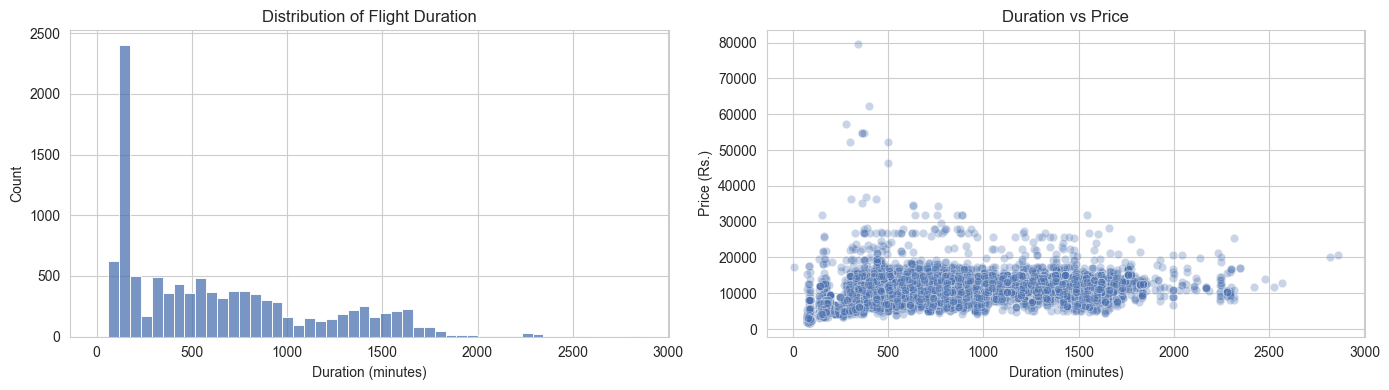

Correlation between Duration and Price: 0.51


In [46]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(eda_df['Duration_Mins'], bins=50, color=BAR_COLOR, ax=axes[0])
axes[0].set_title('Distribution of Flight Duration')
axes[0].set_xlabel('Duration (minutes)')

sns.scatterplot(data=eda_df, x='Duration_Mins', y='Price', alpha=0.3, color=BAR_COLOR, ax=axes[1])
axes[1].set_title('Duration vs Price')
axes[1].set_xlabel('Duration (minutes)')
axes[1].set_ylabel('Price (Rs.)')

plt.tight_layout()
plt.show()

print('Correlation between Duration and Price:', round(eda_df['Duration_Mins'].corr(eda_df['Price']), 2))

### Total_Stops

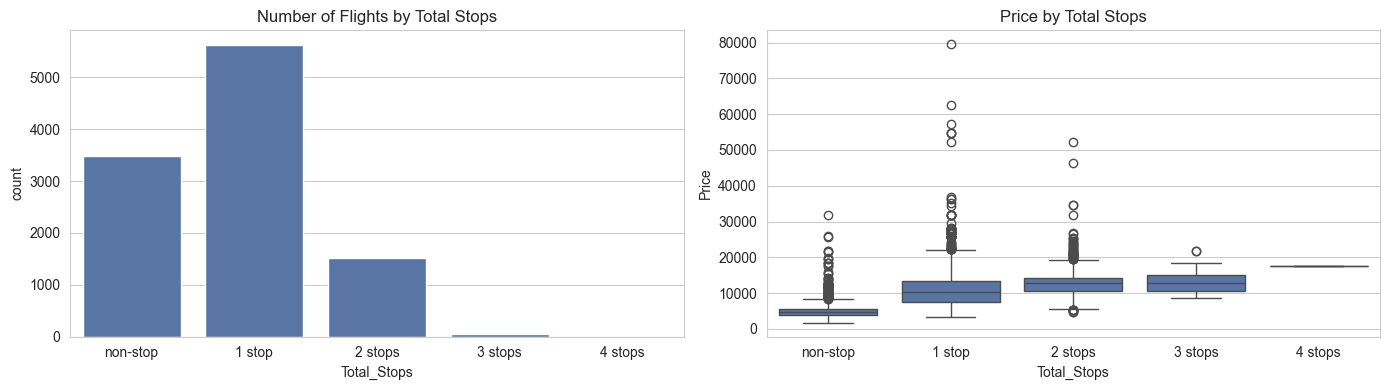

,count,median
Total_Stops,,
non-stop,3491,4667.0
1 stop,5625,10262.0
2 stops,1520,12760.0
3 stops,45,12954.0
4 stops,1,17686.0


In [47]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
stop_order = ['non-stop', '1 stop', '2 stops', '3 stops', '4 stops']

sns.countplot(data=eda_df, x='Total_Stops', order=stop_order, color=BAR_COLOR, ax=axes[0])
axes[0].set_title('Number of Flights by Total Stops')

sns.boxplot(data=eda_df, x='Total_Stops', y='Price', order=stop_order, color=BAR_COLOR, ax=axes[1])
axes[1].set_title('Price by Total Stops')

plt.tight_layout()
plt.show()

eda_df.groupby('Total_Stops')['Price'].agg(['count', 'median']).loc[stop_order]

### Additional_Info

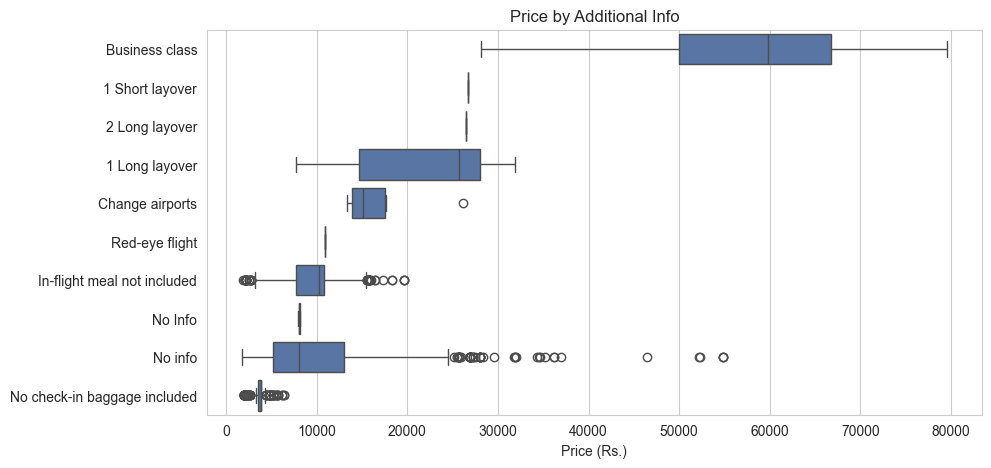

Additional_Info
No info                         8345
In-flight meal not included     1982
No check-in baggage included     320
1 Long layover                    19
Change airports                    7
Business class                     4
No Info                            3
1 Short layover                    1
Red-eye flight                     1
2 Long layover                     1
Name: count, dtype: int64

In [49]:
plt.figure(figsize=(10, 5))
info_order = eda_df.groupby('Additional_Info')['Price'].median().sort_values(ascending=False).index
sns.boxplot(data=eda_df, x='Price', y='Additional_Info', order=info_order, color=BAR_COLOR)
plt.title('Price by Additional Info')
plt.xlabel('Price (Rs.)')
plt.ylabel('')
plt.show()

eda_df['Additional_Info'].value_counts()

### Correlation analysis (numerical features)

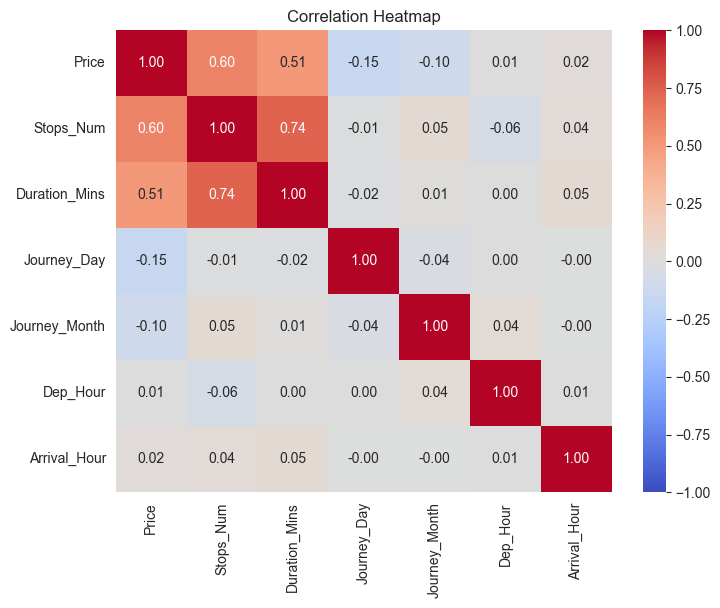

In [50]:
# Convert stops to numbers only for this correlation check
stops_map = {'non-stop': 0, '1 stop': 1, '2 stops': 2, '3 stops': 3, '4 stops': 4}
eda_df['Stops_Num'] = eda_df['Total_Stops'].map(stops_map)

corr_cols = ['Price', 'Stops_Num', 'Duration_Mins', 'Journey_Day', 'Journey_Month', 'Dep_Hour', 'Arrival_Hour']
corr = eda_df[corr_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap')
plt.show()

# 4. Data Preprocessing & Feature Engineering

In [51]:
data = df.copy()
print('Starting shape:', data.shape)

Starting shape: (10683, 11)


### Missing values


In [53]:
data = data.dropna()
print('Shape after removing missing values:', data.shape)
print('Missing values left:', data.isnull().sum().sum())

Shape after removing missing values: (10682, 11)
Missing values left: 0


### Duplicate records



In [55]:
print('Duplicates before:', data.duplicated().sum())
data = data.drop_duplicates()
print('Shape after removing duplicates:', data.shape)

Duplicates before: 220
Shape after removing duplicates: (10462, 11)


### Fix inconsistent category labels


In [56]:
data['Destination'] = data['Destination'].replace('New Delhi', 'Delhi')
data['Additional_Info'] = data['Additional_Info'].replace('No Info', 'No info')

print(data['Destination'].value_counts())
print()
print(data['Additional_Info'].value_counts())

Destination
Cochin       4345
Banglore     2860
Delhi        2179
Hyderabad     697
Kolkata       381
Name: count, dtype: int64

Additional_Info
No info                         8185
In-flight meal not included     1926
No check-in baggage included     318
1 Long layover                    19
Change airports                    7
Business class                     4
1 Short layover                    1
Red-eye flight                     1
2 Long layover                     1
Name: count, dtype: int64


### Date_of_Journey -> Journey_Day, Journey_Month

In [57]:
journey_date = pd.to_datetime(data['Date_of_Journey'], format='%d/%m/%Y')
data['Journey_Day'] = journey_date.dt.day
data['Journey_Month'] = journey_date.dt.month

data[['Date_of_Journey', 'Journey_Day', 'Journey_Month']].head()

,Date_of_Journey,Journey_Day,Journey_Month
0,24/03/2019,24,3
1,1/05/2019,1,5
2,9/06/2019,9,6
3,12/05/2019,12,5
4,01/03/2019,1,3


###  Dep_Time -> Dep_Hour, Dep_Min

In [58]:
dep_time = pd.to_datetime(data['Dep_Time'], format='%H:%M')
data['Dep_Hour'] = dep_time.dt.hour
data['Dep_Min'] = dep_time.dt.minute

data[['Dep_Time', 'Dep_Hour', 'Dep_Min']].head()

,Dep_Time,Dep_Hour,Dep_Min
0,22:20,22,20
1,05:50,5,50
2,09:25,9,25
3,18:05,18,5
4,16:50,16,50


###  Arrival_Time -> Arrival_Hour, Arrival_Min

In [59]:
arrival_clock = data['Arrival_Time'].str.split(' ').str[0]     # '01:10 22 Mar' -> '01:10'
arrival_time = pd.to_datetime(arrival_clock, format='%H:%M')
data['Arrival_Hour'] = arrival_time.dt.hour
data['Arrival_Min'] = arrival_time.dt.minute

data[['Arrival_Time', 'Arrival_Hour', 'Arrival_Min']].head()

,Arrival_Time,Arrival_Hour,Arrival_Min
0,01:10 22 Mar,1,10
1,13:15,13,15
2,04:25 10 Jun,4,25
3,23:30,23,30
4,21:35,21,35


### Duration -> Duration_Mins

In [60]:
data['Duration_Mins'] = data['Duration'].apply(duration_to_minutes)

data[['Duration', 'Duration_Mins']].head()

,Duration,Duration_Mins
0,2h 50m,170
1,7h 25m,445
2,19h,1140
3,5h 25m,325
4,4h 45m,285


### Remove impossible durations

In [ ]:
# Removing suspecious rows
print(data[data['Duration_Mins'] < 60][['Airline', 'Source', 'Destination', 'Route', 'Dep_Time', 'Arrival_Time', 'Duration', 'Total_Stops', 'Price']])

data = data[data['Duration_Mins'] >= 60]
print('\nShape after removing impossible durations:', data.shape)

### Total_Stops -> number

In [61]:
stops_map = {'non-stop': 0, '1 stop': 1, '2 stops': 2, '3 stops': 3, '4 stops': 4}
data['Total_Stops'] = data['Total_Stops'].map(stops_map)

data['Total_Stops'].value_counts().sort_index()

Total_Stops
0    3475
1    5625
2    1318
3      43
4       1
Name: count, dtype: int64

### Outliers in Price
We use the **IQR method** to find unusually expensive tickets: anything above `Q3 + 1.5 * IQR`.

In [62]:
Q1 = data['Price'].quantile(0.25)
Q3 = data['Price'].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR

outliers = data[data['Price'] > upper_limit]
print('Upper limit      :', upper_limit)
print('Number of outliers:', len(outliers), f'({len(outliers) / len(data) * 100:.2f}% of data)')
print('\nAirlines of the outlier tickets:')
print(outliers['Airline'].value_counts())
print('\nAdditional info of the outlier tickets:')
print(outliers['Additional_Info'].value_counts())

Upper limit      : 23025.875
Number of outliers: 94 (0.90% of data)

Airlines of the outlier tickets:
Airline
Jet Airways             62
Air India               15
Multiple carriers       10
Jet Airways Business     6
SpiceJet                 1
Name: count, dtype: int64

Additional info of the outlier tickets:
Additional_Info
No info            77
1 Long layover     10
Business class      4
1 Short layover     1
Change airports     1
2 Long layover      1
Name: count, dtype: int64


### Drop columns that are not important

In [63]:
data = data.drop(columns=['Date_of_Journey', 'Dep_Time', 'Arrival_Time', 'Duration', 'Route'])

print('Final shape:', data.shape)
data.head()

Final shape: (10462, 13)


,Airline,Source,Destination,Total_Stops,Additional_Info,Price,Journey_Day,Journey_Month,Dep_Hour,Dep_Min,Arrival_Hour,Arrival_Min,Duration_Mins
0,IndiGo,Banglore,Delhi,0,No info,3897,24,3,22,20,1,10,170
1,Air India,Kolkata,Banglore,2,No info,7662,1,5,5,50,13,15,445
2,Jet Airways,Delhi,Cochin,2,No info,13882,9,6,9,25,4,25,1140
3,IndiGo,Kolkata,Banglore,1,No info,6218,12,5,18,5,23,30,325
4,IndiGo,Banglore,Delhi,1,No info,13302,1,3,16,50,21,35,285


In [64]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10462 entries, 0 to 10682
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10462 non-null  object
 1   Source           10462 non-null  object
 2   Destination      10462 non-null  object
 3   Total_Stops      10462 non-null  int64 
 4   Additional_Info  10462 non-null  object
 5   Price            10462 non-null  int64 
 6   Journey_Day      10462 non-null  int32 
 7   Journey_Month    10462 non-null  int32 
 8   Dep_Hour         10462 non-null  int32 
 9   Dep_Min          10462 non-null  int32 
 10  Arrival_Hour     10462 non-null  int32 
 11  Arrival_Min      10462 non-null  int32 
 12  Duration_Mins    10462 non-null  int64 
dtypes: int32(6), int64(3), object(4)
memory usage: 899.1+ KB


# 5. Feature Encoding & Feature Selection

### Which columns still need encoding?
After preprocessing, 4 columns are still text: **Airline, Source, Destination, Additional_Info**.

### Why One-Hot Encoding?
- These categories have **no natural order** (IndiGo is not "bigger" than SpiceJet).
- **Label encoding** (IndiGo = 0, SpiceJet = 1, ...) would make the model think there is an order, which is wrong, especially for Linear Regression.
- **One-hot encoding** creates one 0/1 column per category, so there is no fake order.
- The number of categories is small (12 + 5 + 5 + 9), so one-hot encoding creates only ~30 columns - that is manageable.

`Total_Stops` was already ordinal-encoded (0-4) because it **does** have an order.

### Important: when do we encode?
We **decide** the encoding here, but we **fit** the encoder only on the training data after the split (Section 6).
This way nothing from the test set is used to prepare the training data (no data leakage).

In [65]:
# Separate the features (X) and the target (y)
X = data.drop(columns=['Price'])
y = data['Price']

categorical_cols = ['Airline', 'Source', 'Destination', 'Additional_Info']
numerical_cols = ['Total_Stops', 'Journey_Day', 'Journey_Month', 'Dep_Hour', 'Dep_Min',
                  'Arrival_Hour', 'Arrival_Min', 'Duration_Mins']

print('Categorical features:', categorical_cols)
print('Numerical features  :', numerical_cols)
print('X shape:', X.shape, '| y shape:', y.shape)

Categorical features: ['Airline', 'Source', 'Destination', 'Additional_Info']
Numerical features  : ['Total_Stops', 'Journey_Day', 'Journey_Month', 'Dep_Hour', 'Dep_Min', 'Arrival_Hour', 'Arrival_Min', 'Duration_Mins']
X shape: (10462, 12) | y shape: (10462,)


# 6. Train-Test Split

### Why split the data?
The goal is to predict prices of **new flights the model has never seen**. If we test the model on the same data it trained on,
it could simply "remember" the answers and look perfect. So we keep **20% of the data hidden** as a test set and only use it at the end
to measure how well the model **generalizes**.

### How we avoid data leakage
- Split **before** fitting the encoder.
- Fit the One-Hot Encoder on **training data only**, then use it to transform both train and test.
- Hyperparameter tuning (Section 10) uses **cross-validation on the training data only**. The test set is used only for final evaluation.
- `random_state=42` makes the split reproducible.

In [66]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print('X_train:', X_train.shape, '| y_train:', y_train.shape)
print('X_test :', X_test.shape, '| y_test :', y_test.shape)

X_train: (8369, 12) | y_train: (8369,)
X_test : (2093, 12) | y_test : (2093,)


### Apply One-Hot Encoding (fit on train only)
- `handle_unknown='ignore'`: if a category appears in test / real use that was not in training (e.g. a very rare airline),
  the encoder sets all its columns to 0 instead of crashing.
- `sparse_output=False`: returns a normal array that is easy to look at.

In [67]:
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
encoder.fit(X_train[categorical_cols])          # learn the categories from TRAINING data only

encoded_col_names = encoder.get_feature_names_out(categorical_cols)
print('Number of one-hot columns:', len(encoded_col_names))


def encode_features(X_part):
    # Returns numeric columns + one-hot encoded categorical columns as one DataFrame
    encoded = encoder.transform(X_part[categorical_cols])
    encoded_df = pd.DataFrame(encoded, columns=encoded_col_names, index=X_part.index)
    return pd.concat([X_part[numerical_cols], encoded_df], axis=1)


X_train_final = encode_features(X_train)
X_test_final = encode_features(X_test)

print('X_train_final:', X_train_final.shape)
print('X_test_final :', X_test_final.shape)
X_train_final.head()

Number of one-hot columns: 31
X_train_final: (8369, 39)
X_test_final : (2093, 39)


,Total_Stops,Journey_Day,Journey_Month,Dep_Hour,Dep_Min,Arrival_Hour,Arrival_Min,Duration_Mins,Airline_Air Asia,Airline_Air India,Airline_GoAir,Airline_IndiGo,Airline_Jet Airways,Airline_Jet Airways Business,Airline_Multiple carriers,Airline_Multiple carriers Premium economy,Airline_SpiceJet,Airline_Trujet,Airline_Vistara,Airline_Vistara Premium economy,Source_Banglore,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Destination_Banglore,Destination_Cochin,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Additional_Info_1 Long layover,Additional_Info_1 Short layover,Additional_Info_2 Long layover,Additional_Info_Business class,Additional_Info_Change airports,Additional_Info_In-flight meal not included,Additional_Info_No check-in baggage included,Additional_Info_No info,Additional_Info_Red-eye flight
6727,0,1,5,9,10,10,40,90,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6322,1,9,5,10,0,19,0,540,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6874,1,1,6,10,0,1,30,930,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3493,1,6,5,8,10,13,0,290,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
611,1,21,3,23,0,19,15,1215,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


# 7. Model Building

To predict flight ticket prices, multiple regression models are selected to compare their performance on the dataset.

* **Linear Regression:** Used as a baseline model to understand the linear relationship between flight features and ticket prices.
* **Decision Tree Regressor:** Used to capture non-linear relationships and interactions between different flight features.
* **Random Forest Regressor:** Uses multiple decision trees to improve prediction stability and reduce the risk of overfitting.
* **Gradient Boosting Regressor:** Builds models sequentially, where each new model focuses on reducing the errors made by the previous models.

All models are trained using the same training dataset and will be evaluated using the same performance metrics. The model with the best evaluation results will be considered for the final prediction.


In [68]:
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
}

for name, model in models.items():
    model.fit(X_train_final, y_train)
    print(f'{name} trained.')

Linear Regression trained.
Decision Tree trained.
Random Forest trained.
Gradient Boosting trained.


# 8. Model Evaluation

In [69]:
def regression_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return mae, mse, rmse, r2


results = []
for name, model in models.items():
    train_pred = model.predict(X_train_final)
    test_pred = model.predict(X_test_final)

    train_mae, train_mse, train_rmse, train_r2 = regression_metrics(y_train, train_pred)
    test_mae, test_mse, test_rmse, test_r2 = regression_metrics(y_test, test_pred)

    results.append({
        'Model': name,
        'Train R2': train_r2,
        'Test R2': test_r2,
        'Train RMSE': train_rmse,
        'Test RMSE': test_rmse,
        'Test MAE': test_mae,
        'Test MSE': test_mse,
    })

results_df = pd.DataFrame(results).set_index('Model')
results_df.round(3)

,Train R2,Test R2,Train RMSE,Test RMSE,Test MAE,Test MSE
Model,,,,,,
Linear Regression,0.688,0.649,2589.042,2705.416,1794.902,7319275.761
Decision Tree,0.996,0.856,289.398,1735.475,752.949,3011872.774
Random Forest,0.982,0.895,614.236,1481.328,673.176,2194332.240
Gradient Boosting,0.838,0.802,1867.587,2031.179,1261.798,4125688.918


### Cross-validation (checking stability on the training data)

In [70]:
cv_means = []
cv_stds = []
for name, model in models.items():
    scores = cross_val_score(model, X_train_final, y_train, cv=5, scoring='r2')
    cv_means.append(scores.mean())
    cv_stds.append(scores.std())

results_df['CV R2 (mean)'] = cv_means
results_df['CV R2 (std)'] = cv_stds

# Overfitting gap = how much better the model does on train than on test
results_df['Overfit Gap (Train R2 - Test R2)'] = results_df['Train R2'] - results_df['Test R2']

comparison_table = results_df[['Train R2', 'Test R2', 'Overfit Gap (Train R2 - Test R2)', 'CV R2 (mean)', 'CV R2 (std)',
                               'Test MAE', 'Test RMSE', 'Test MSE']]
comparison_table.sort_values('Test RMSE').round(3)

,Train R2,Test R2,Overfit Gap (Train R2 - Test R2),CV R2 (mean),CV R2 (std),Test MAE,Test RMSE,Test MSE
Model,,,,,,,,
Random Forest,0.982,0.895,0.088,0.891,0.009,673.176,1481.328,2194332.240
Decision Tree,0.996,0.856,0.141,0.834,0.024,752.949,1735.475,3011872.774
Gradient Boosting,0.838,0.802,0.036,0.819,0.028,1261.798,2031.179,4125688.918
Linear Regression,0.688,0.649,0.040,0.680,0.035,1794.902,2705.416,7319275.761


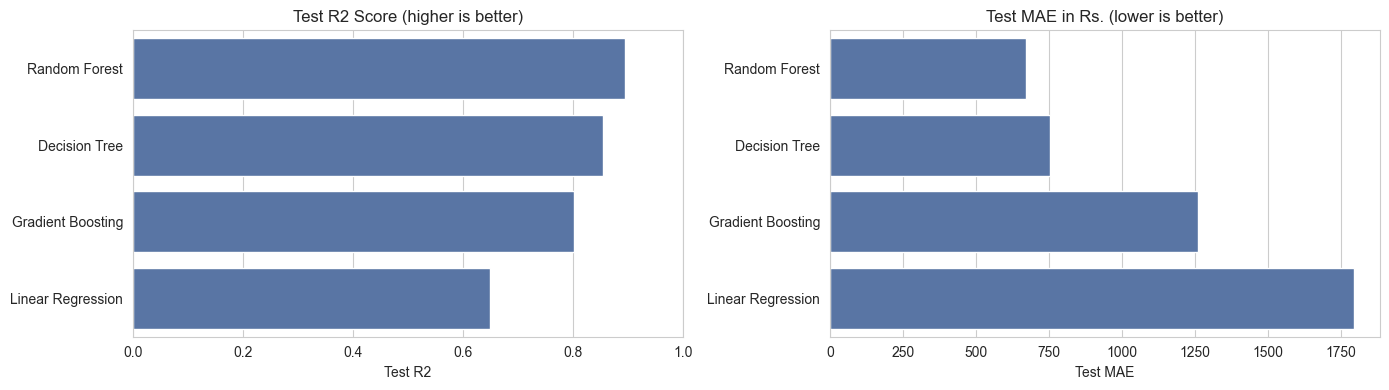

In [71]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
order = results_df.sort_values('Test RMSE').index

sns.barplot(x=results_df.loc[order, 'Test R2'], y=order, color=BAR_COLOR, ax=axes[0])
axes[0].set_title('Test R2 Score (higher is better)')
axes[0].set_xlim(0, 1)
axes[0].set_ylabel('')

sns.barplot(x=results_df.loc[order, 'Test MAE'], y=order, color=BAR_COLOR, ax=axes[1])
axes[1].set_title('Test MAE in Rs. (lower is better)')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

## Interpretation of Model Comparison

* **Linear Regression:** Train R² ≈ 0.69 and Test R² ≈ 0.65. Both scores are relatively low, which indicates **underfitting**. The model cannot capture the complex patterns in flight prices.

* **Decision Tree:** Train R² ≈ 0.996, but Test R² ≈ 0.86. The large difference shows **overfitting**, meaning the model performs extremely well on training data but less well on unseen data.

* **Gradient Boosting:** Train R² ≈ 0.84 and Test R² ≈ 0.80. The model is reasonably stable but slightly **underfits** the data with its default settings.

* **Random Forest:** Gives the **best test performance**, with Test R² ≈ 0.895 and MAE ≈ ₹673. It also has a strong cross-validation score. However, there is still some difference between training and test performance, so tuning may help reduce overfitting.

### Conclusion

Based on the current results, **Random Forest performs best on the test data** and will be considered for further tuning.


## 9. Model Selection

We compared four different regression models to find which model predicts flight prices better.

* **Linear Regression:** Simple model, but its accuracy was lower.
* **Decision Tree:** Performed better, but showed signs of overfitting.
* **Gradient Boosting:** Gave reasonable results but was not the best.
* **Random Forest:** Gave the **best results on the test data** with the lowest errors and highest R² score.

### Selected Model: Random Forest Regressor

Based on the results, we selected **Random Forest Regressor** as our final model because it performed better than the other models in our comparison.

We will further tune this model to improve its performan


# 10. Hyperparameter Tuning (Random Forest)

In [73]:
param_distributions = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': [1.0, 'sqrt', 0.5],
}

random_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_distributions=param_distributions,
    n_iter=20,                                # try 20 random combinations
    cv=5,                                     # 5-fold cross-validation on training data
    scoring='neg_root_mean_squared_error',
    random_state=42,
    n_jobs=-1,                                # use all CPU cores
    verbose=1,
)

random_search.fit(X_train_final, y_train)

print('Best parameters:', random_search.best_params_)
print('Best CV RMSE   :', round(-random_search.best_score_, 2))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best parameters: {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 30}
Best CV RMSE   : 1484.23


In [75]:
# Compare with the default Random Forest using the SAME 5-fold CV on training data (test set still unused)
default_rf_cv_rmse = -cross_val_score(RandomForestRegressor(random_state=42, n_jobs=-1),
                                      X_train_final, y_train, cv=5,
                                      scoring='neg_root_mean_squared_error').mean()

print('Default Random Forest - CV RMSE:', round(default_rf_cv_rmse, 2))
print('Tuned Random Forest   - CV RMSE:', round(-random_search.best_score_, 2))

Default Random Forest - CV RMSE: 1527.87
Tuned Random Forest   - CV RMSE: 1484.23


## Result of Tuning

- **Best parameters:** `n_estimators=300`, `max_depth=30`, `max_features=0.5`, `min_samples_split=5`, `min_samples_leaf=1`
- **Default RMSE (5-fold CV):** ~₹1,528
- **Tuned RMSE (5-fold CV):** ~₹1,484
- **Improvement:** ~2.9%

The tuned Random Forest performed slightly better in cross-validation, so we selected it as the final model.

# 11. Final Model Evaluation (on the unseen test set)

In [78]:
final_model = random_search.best_estimator_     # already re-trained on the full training data by RandomizedSearchCV

final_train_pred = final_model.predict(X_train_final)
final_test_pred = final_model.predict(X_test_final)

train_mae, train_mse, train_rmse, train_r2 = regression_metrics(y_train, final_train_pred)
test_mae, test_mse, test_rmse, test_r2 = regression_metrics(y_test, final_test_pred)

final_results = pd.DataFrame({
    'Default Random Forest (Test)': results_df.loc['Random Forest', ['Test MAE', 'Test RMSE', 'Test R2']].values,
    'Tuned Random Forest (Test)': [test_mae, test_rmse, test_r2],
    'Tuned Random Forest (Train)': [train_mae, train_rmse, train_r2],
}, index=['MAE', 'RMSE', 'R2'])

final_results.round(3)

,Default Random Forest (Test),Tuned Random Forest (Test),Tuned Random Forest (Train)
MAE,673.176,692.424,402.344
RMSE,1481.328,1475.609,855.490
R2,0.895,0.896,0.966


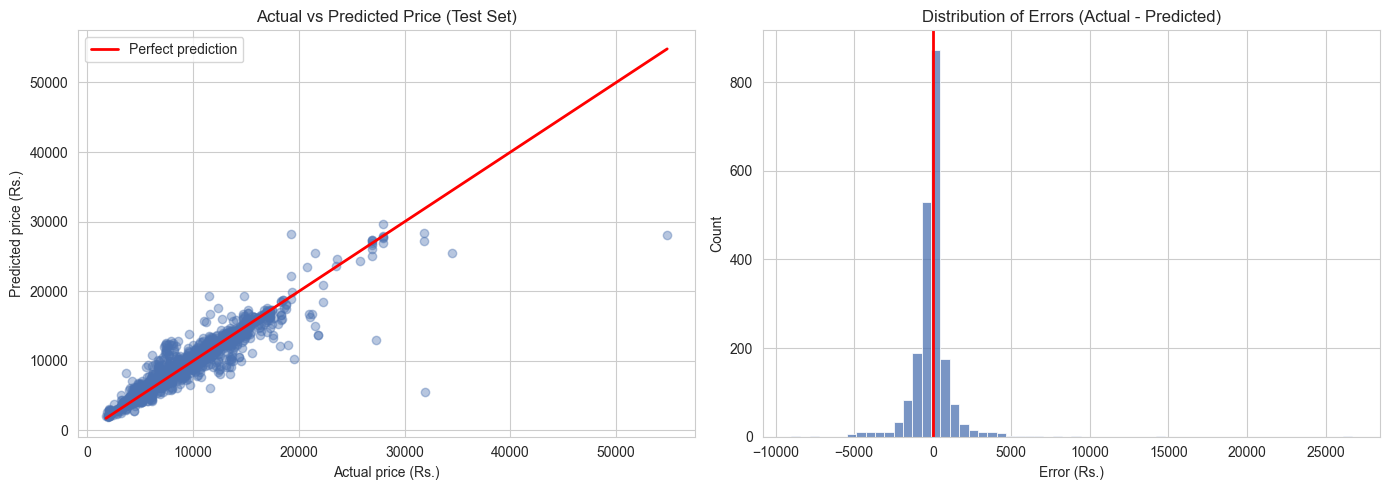

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs Predicted: points close to the red line are good predictions
axes[0].scatter(y_test, final_test_pred, alpha=0.4, color=BAR_COLOR)
line_limits = [y_test.min(), y_test.max()]
axes[0].plot(line_limits, line_limits, color='red', linewidth=2, label='Perfect prediction')
axes[0].set_title('Actual vs Predicted Price (Test Set)')
axes[0].set_xlabel('Actual price (Rs.)')
axes[0].set_ylabel('Predicted price (Rs.)')
axes[0].legend()

# Residuals = actual - predicted
residuals = y_test - final_test_pred
sns.histplot(residuals, bins=60, color=BAR_COLOR, ax=axes[1])
axes[1].axvline(0, color='red', linewidth=2)
axes[1].set_title('Distribution of Errors (Actual - Predicted)')
axes[1].set_xlabel('Error (Rs.)')

plt.tight_layout()
plt.show()

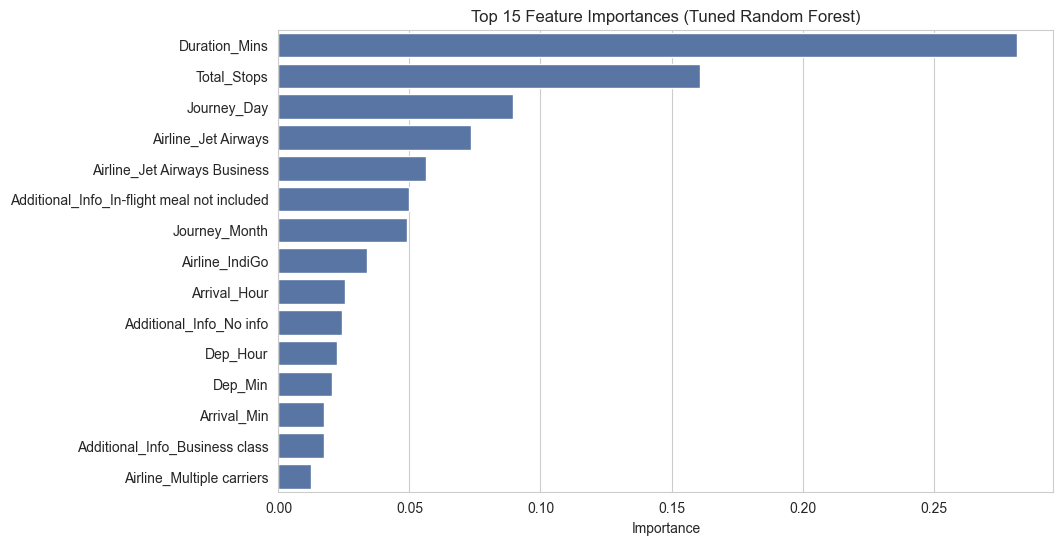

Duration_Mins                                  0.282
Total_Stops                                    0.161
Journey_Day                                    0.089
Airline_Jet Airways                            0.073
Airline_Jet Airways Business                   0.056
Additional_Info_In-flight meal not included    0.050
Journey_Month                                  0.049
Airline_IndiGo                                 0.034
Arrival_Hour                                   0.026
Additional_Info_No info                        0.024
Dep_Hour                                       0.022
Dep_Min                                        0.021
Arrival_Min                                    0.017
Additional_Info_Business class                 0.017
Airline_Multiple carriers                      0.012
dtype: float64

In [80]:
# Which features does the final model rely on the most?
importances = pd.Series(final_model.feature_importances_, index=X_train_final.columns)
top_features = importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_features.values, y=top_features.index, color=BAR_COLOR)
plt.title('Top 15 Feature Importances (Tuned Random Forest)')
plt.xlabel('Importance')
plt.ylabel('')
plt.show()

top_features.round(3)

## Final Evaluation Insights

* **R² = 0.896**, **RMSE ≈ ₹1,476**, and **MAE ≈ ₹692** on the test data.
* On average, the model's prediction is around **₹700 away** from the actual price.
* The tuned model performed **almost the same as the default Random Forest**.
* **Overfitting was reduced**, as the train-test R² gap became smaller.
* Most predictions are close to the actual prices. For very expensive tickets, the model sometimes **under-predicts**.
* The errors are mostly centered around **0**, showing no major prediction bias.
* **Duration_Mins** and **Total_Stops** are the most important features, followed by **Journey_Day, airline features, Journey_Month, and Additional_Info**.


# 12. Sample Prediction

In [81]:
def predict_flight_price(airline, source, destination, journey_date, dep_time, arrival_time,
                         duration, total_stops, additional_info='No info'):
    # Put the user input into a one-row DataFrame with the same raw columns as the dataset
    flight = pd.DataFrame({
        'Airline': [airline],
        'Source': [source],
        'Destination': [destination.replace('New Delhi', 'Delhi')],
        'Additional_Info': [additional_info.replace('No Info', 'No info')],
    })

    # Same feature engineering as Section 4
    date = pd.to_datetime(journey_date, format='%d/%m/%Y')
    flight['Journey_Day'] = date.day
    flight['Journey_Month'] = date.month

    dep = pd.to_datetime(dep_time, format='%H:%M')
    flight['Dep_Hour'] = dep.hour
    flight['Dep_Min'] = dep.minute

    arr = pd.to_datetime(arrival_time.split(' ')[0], format='%H:%M')
    flight['Arrival_Hour'] = arr.hour
    flight['Arrival_Min'] = arr.minute

    flight['Duration_Mins'] = duration_to_minutes(duration)
    flight['Total_Stops'] = stops_map[total_stops]

    # Same encoding as the training data, then predict
    flight_final = encode_features(flight)
    return final_model.predict(flight_final)[0]

In [82]:
# Example 1: a morning IndiGo non-stop flight from Banglore to Delhi
price_1 = predict_flight_price(
    airline='IndiGo', source='Banglore', destination='New Delhi',
    journey_date='24/03/2019', dep_time='06:20', arrival_time='09:10',
    duration='2h 50m', total_stops='non-stop')

# Example 2: a Jet Airways 1-stop flight from Delhi to Cochin
price_2 = predict_flight_price(
    airline='Jet Airways', source='Delhi', destination='Cochin',
    journey_date='06/06/2019', dep_time='09:00', arrival_time='04:25 07 Jun',
    duration='19h 25m', total_stops='1 stop', additional_info='In-flight meal not included')

print(f'Example 1 - IndiGo, BLR -> DEL, non-stop     : predicted price = Rs. {price_1:,.0f}')
print(f'Example 2 - Jet Airways, DEL -> COK, 1 stop  : predicted price = Rs. {price_2:,.0f}')

Example 1 - IndiGo, BLR -> DEL, non-stop     : predicted price = Rs. 5,525
Example 2 - Jet Airways, DEL -> COK, 1 stop  : predicted price = Rs. 10,367


In [83]:
# Sanity check: take a real flight from the TEST set (raw text columns from the original df) and compare
sample_index = X_test.index[0]
raw = df.loc[sample_index]
print(raw, '\n')

predicted = predict_flight_price(raw['Airline'], raw['Source'], raw['Destination'], raw['Date_of_Journey'],
                                 raw['Dep_Time'], raw['Arrival_Time'], raw['Duration'], raw['Total_Stops'],
                                 raw['Additional_Info'])

print(f'Actual price   : Rs. {raw["Price"]:,.0f}')
print(f'Predicted price: Rs. {predicted:,.0f}')

Airline                Jet Airways
Date_of_Journey         06/03/2019
Source                    Banglore
Destination              New Delhi
Route              BLR → BOM → DEL
Dep_Time                     08:00
Arrival_Time          08:15 07 Mar
Duration                   24h 15m
Total_Stops                 1 stop
Additional_Info            No info
Price                        17996
Name: 2150, dtype: object 

Actual price   : Rs. 17,996
Predicted price: Rs. 15,349


In [84]:
# A fair picture: actual vs predicted for the first 10 flights of the test set
sample_check = pd.DataFrame({
    'Airline': X_test['Airline'].values[:10],
    'Actual Price': y_test.values[:10],
    'Predicted Price': final_test_pred[:10].round(0),
})
sample_check['Error'] = sample_check['Actual Price'] - sample_check['Predicted Price']
sample_check

,Airline,Actual Price,Predicted Price,Error
0,Jet Airways,17996,15349.0,2647.0
1,SpiceJet,3873,3877.0,-4.0
2,IndiGo,4462,4263.0,199.0
3,Jet Airways,2228,2612.0,-384.0
4,SpiceJet,4991,4296.0,695.0
5,Multiple carriers,7670,7665.0,5.0
6,Multiple carriers,14086,14475.0,-389.0
7,IndiGo,6386,6257.0,129.0
8,IndiGo,6628,6305.0,323.0
9,Air India,6934,6419.0,515.0


## Observation

* The **IndiGo non-stop** flight is predicted at around **₹5,525**, while the **Jet Airways 1-stop** flight is predicted at around **₹10,367**.
* For the test flight with **Jet Airways, 24h 15m duration and 1 stop**, the model predicted **₹15,349** compared to the actual price of **₹17,996**.
* In the first 10 test flights, **8 out of 10 predictions** are within approximately **₹550** of the actual price.
* The larger error occurs for the **higher-priced flight**, which is consistent with the Actual vs Predicted plot.


# 13. Challenges & Solutions

### 1. Missing Values

* Found 1 row with missing `Route` and `Total_Stops`.
* Dropped the row because the number of missing values was very small.

### 2. Duplicate Records

* Found 220 duplicate records.
* Removed them using `drop_duplicates()`.

### 3. Mixed Data Types

* Date, time, duration, and stops were stored as text.
* Converted them into numerical values for ML.

### 4. Date Column

* Extracted `Journey_Day` and `Journey_Month` from `Date_of_Journey`.
* The year was not used because all records were from 2019.

### 5. Time Columns

* Extracted hour and minute from arrival and departure times.
* This made the time information easier to use in the model.

### 6. Duration

* Duration was available in different formats s


# 14. Final Conclusion

### Major EDA Findings

* The dataset contains **10,683 flight records** from March to June 2019.
* Flight prices are **right-skewed**, with some very expensive tickets.
* **Airline** has a strong effect on price. Jet Airways and business-class flights are generally more expensive.
* **More stops and longer duration** are associated with higher prices.
* **March** was the most expensive month, while **April** was the cheapest.
* The dataset also had some data quality issues such as missing values, duplicates, inconsistent labels, and mixed formats.

### Important Features

The most important features were:

* `Duration_Mins`
* `Total_Stops`
* `Journey_Day`
* `Airline`
* `Journey_Month`
* `Additional_Info`

### Models Tested

Four regression models were tested:

* **Linear Regression:** Underfitted the data.
* **Decision Tree:** Performed well but showed overfitting.
* **Random Forest:** Gave the best overall results.
* **Gradient Boosting:** Gave reasonable results but was not the best.

### Final Model

The **Random Forest Regressor** was selected as the final model.

It was further improved using **RandomizedSearchCV** with hyperparameter tuning.

### Final Results

* **R²:** 0.896
* **MAE:** ~₹692
* **RMSE:** ~₹1,476

The model explains about **90% of the variation in flight prices**, and the average prediction error is around **₹700**.

### What This Project Demonstrates

This project covers a complete machine learning workflow:

**EDA → Data Cleaning → Feature Engineering → Encoding → Model Training → Model Comparison → Tuning → Final Evaluation → Prediction**

It also demonstrates how to handle missing values, duplicates, outliers, categorical data, and
